# 01 · Exploratory data analysis
Half-hourly wholesale prices at Mt Roskill (`ROS1101`), Jan 2023 to Jun 2026, merged with Auckland temperature and Manawatū wind.
Goal: understand the price patterns before building a forecast model.

## Setup
Load libraries, set a consistent chart style, and read the merged dataset built by `src/build_dataset.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
# Chart style: thin lines, light grid, no top/right borders
BLUE, ORANGE, LIGHT_BLUE = "#2a78d6", "#eb6834", "#86b6ef"
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e2"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 2, "legend.frameon": False,
})
FIG = "../results/figures"     # where every plot gets saved for the README/portfolio

# Load the merged half-hourly table from step 4
data = pd.read_parquet("../data/processed/merged.parquet")
data.head()

,date,tp,price,akl_temp,mnw_wind
time_nz,,,,,
2023-01-01 00:00:00+13:00,2023-01-01,1,3.10,19.1,24.4
2023-01-01 00:30:00+13:00,2023-01-01,2,4.15,19.4,25.5
2023-01-01 01:00:00+13:00,2023-01-01,3,3.43,19.7,26.6
2023-01-01 01:30:00+13:00,2023-01-01,4,5.77,19.2,26.1
2023-01-01 02:00:00+13:00,2023-01-01,5,4.48,18.7,25.6


## 1. Price over time
Daily mean price across the whole period. Looking for long-term trends and extreme events (e.g. dry-year price spikes).

Most expensive days ($/MWh):
date
07/08/2024    889.0
06/08/2024    871.0
08/08/2024    821.0
05/08/2024    810.0
09/08/2024    787.0


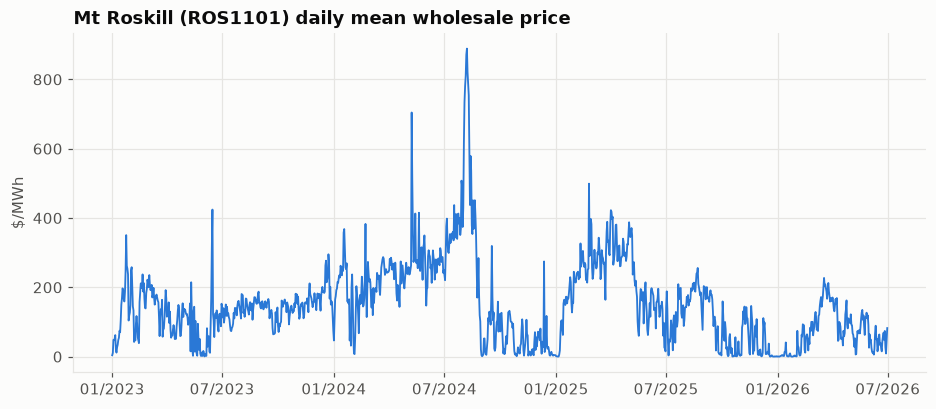

In [3]:
# Collapse 48 half-hours into one row per day: the day's mean, min and max price
daily = data.groupby("date")["price"].agg(["mean", "min", "max"])

fig, ax = plt.subplots()
ax.plot(daily.index, daily["mean"], color=BLUE, linewidth=1.2)
ax.set_title("Mt Roskill (ROS1101) daily mean wholesale price")
ax.set_ylabel("$/MWh")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))   # x-axis labels as MM/YYYY
fig.savefig(f"{FIG}/01_daily_mean_price.png", dpi=150, bbox_inches="tight")

# The 5 most expensive days, dates shown as DD/MM/YYYY
top5 = daily["mean"].nlargest(5)
top5.index = top5.index.strftime("%d/%m/%Y")
print("Most expensive days ($/MWh):\n" + top5.round(0).to_string())

## 2. Typical daily shape
Median price for each trading period, weekday vs weekend. The median shows the *typical* day without spikes distorting it.
This shape is what a battery exploits: charge in the cheap periods, discharge in the expensive ones.

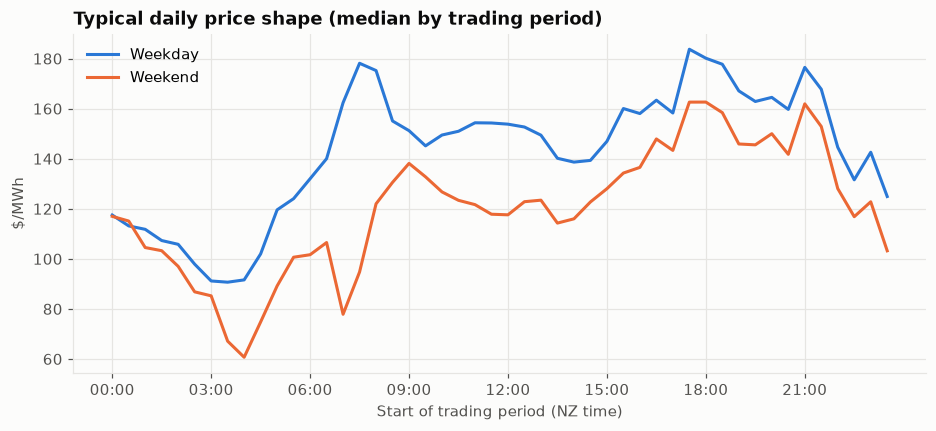

In [4]:
# Label each row Weekday or Weekend (dayofweek: Monday = 0 ... Sunday = 6)
data["day_type"] = np.where(data.index.day_of_week >= 5, "Weekend", "Weekday")

# Median price for each trading period, split by day type.
# Median, not mean, so a few extreme spikes don't distort the "typical" shape.
# unstack() turns the day types into two side-by-side columns
profile = data.groupby(["tp", "day_type"])["price"].median().unstack()

# Relabel trading periods 1..48 as clock times 00:00..23:30
profile.index = (pd.Timestamp("2000-01-01")
                 + pd.to_timedelta((profile.index - 1) * 30, unit="min")).strftime("%H:%M")

fig, ax = plt.subplots()
ax.plot(profile.index, profile["Weekday"], color=BLUE, label="Weekday")
ax.plot(profile.index, profile["Weekend"], color=ORANGE, label="Weekend")
ax.set_xticks(profile.index[::6])                 # a tick every 3 hours
ax.set_title("Typical daily price shape (median by trading period)")
ax.set_ylabel("$/MWh")
ax.set_xlabel("Start of trading period (NZ time)")
ax.legend()
fig.savefig(f"{FIG}/02_daily_profile.png", dpi=150, bbox_inches="tight")

## 3. Monthly level and volatility
Mean and standard deviation of price per month. Seasonality matters for the model (winter demand, hydro lake levels).

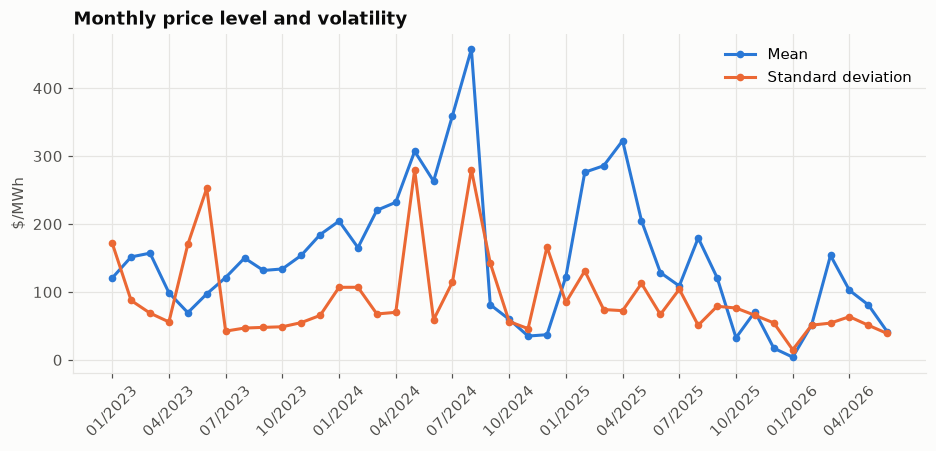

In [5]:
# Mean and standard deviation of price for each calendar month
monthly = data.groupby(data["date"].dt.to_period("M"))["price"].agg(["mean", "std"])
labels = monthly.index.strftime("%m/%Y")

fig, ax = plt.subplots()
ax.plot(labels, monthly["mean"], color=BLUE, marker="o", markersize=4, label="Mean")
ax.plot(labels, monthly["std"], color=ORANGE, marker="o", markersize=4, label="Standard deviation")
ax.set_xticks(labels[::3])                        # label every 3rd month
ax.tick_params(axis="x", rotation=45)
ax.set_title("Monthly price level and volatility")
ax.set_ylabel("$/MWh")
ax.legend()
fig.savefig(f"{FIG}/03_monthly_mean_std.png", dpi=150, bbox_inches="tight")

## 4. Price distribution
How prices are spread, and how often they spike above $500/MWh.
A heavy right tail means squared-error metrics will be dominated by a few extreme periods.

Periods above $500/MWh: 917 (1.5% of all periods)
count    60912.0
mean       150.1
std        148.2
min          0.0
5%           0.0
50%        138.7
95%        354.1
99%        628.0
max       5782.6


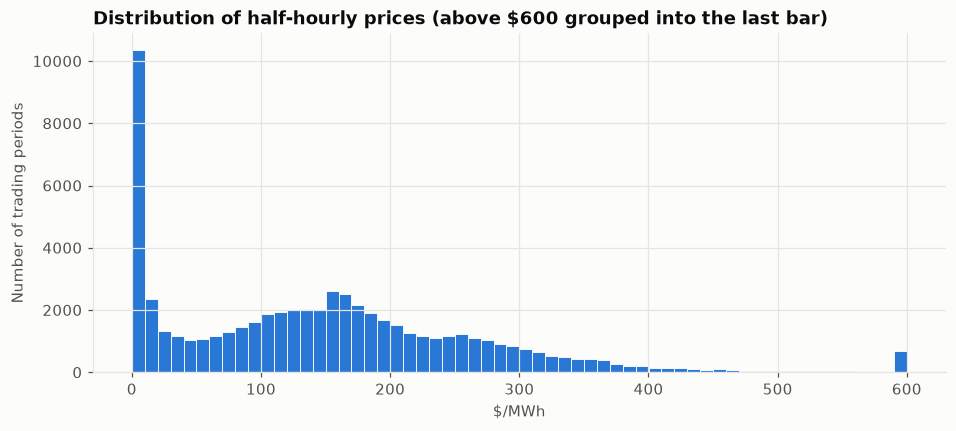

In [6]:
CAP = 600   # prices above this are lumped into the last bar so the main shape stays readable

fig, ax = plt.subplots()
ax.hist(data["price"].clip(upper=CAP), bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.set_title(f"Distribution of half-hourly prices (above ${CAP} grouped into the last bar)")
ax.set_xlabel("$/MWh")
ax.set_ylabel("Number of trading periods")
fig.savefig(f"{FIG}/04_price_histogram.png", dpi=150, bbox_inches="tight")

# How often prices spike, plus the key percentiles
n_high = (data["price"] > 500).sum()
print(f"Periods above $500/MWh: {n_high:,} ({n_high / len(data):.1%} of all periods)")
print(data["price"].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).round(1).to_string())

## 5. Daily price spread
$\operatorname{Spread}$ = $\max_t p_t - \min_t p_t$ for each day: the most a battery could earn per MWh cycled.
Wider spreads = more arbitrage value.

Median daily spread: $158/MWh


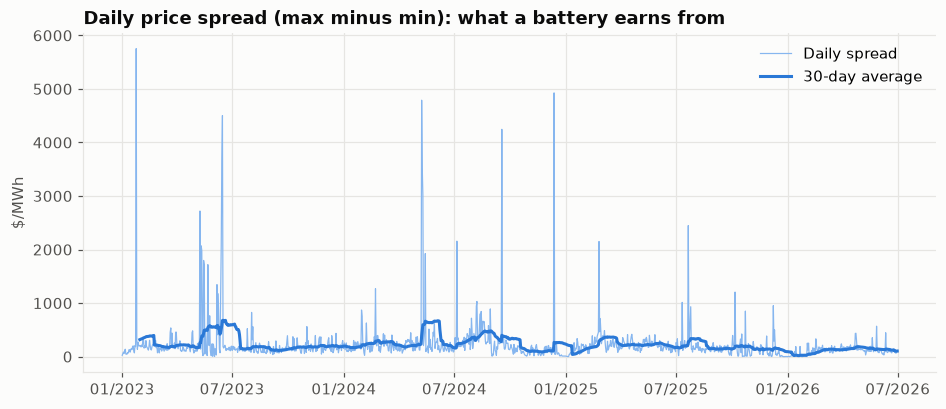

In [7]:
# Daily spread = most expensive half-hour minus cheapest half-hour that day
spread = daily["max"] - daily["min"]

fig, ax = plt.subplots()
ax.plot(spread.index, spread, color=LIGHT_BLUE, linewidth=0.8, label="Daily spread")
ax.plot(spread.index, spread.rolling(30).mean(), color=BLUE, label="30-day average")
ax.set_title("Daily price spread (max minus min): what a battery earns from")
ax.set_ylabel("$/MWh")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.legend()
fig.savefig(f"{FIG}/05_daily_spread.png", dpi=150, bbox_inches="tight")
print(f"Median daily spread: ${spread.median():.0f}/MWh")

## What are the key findings?

1. **Price level shifts between regimes rather than following a smooth seasonal cycle.** Monthly mean price ranged from about \$3/MWh (01/2026) to about \$455/MWh (08/2024). The big highs (mid-2024, early 2025) and lows (late 2024, late 2025 to early 2026) look driven by hydro conditions rather than the calendar, so **recent price lags** and possibly **hydro lake storage** should be strong features.

2. **The typical day has two peaks.** Prices are cheapest around 03:00 to 04:00 (median about \$90 on weekdays, \$60 on weekends), then peak around 07:30 to 08:00 (about \$178) and again at 17:30 to 18:00 (about \$184). Weekends run \$20 to \$40 lower, with a later, smaller morning peak. A battery could potentially cycle **twice a day**.

3. **The distribution is bimodal, with 2 peaks and a reasonably heavy right skew.** About 17% of periods sit near \$0 (the 5th percentile is \$0.00), the main mass is centred near \$150, and 1.5% of periods (917) exceed \$500, up to a maximum of \$5,783. Median \$139, mean \$150, standard deviation \$148. A few spikes would dominate squared-error metrics, so **use absolute error** (MAE) both to train and to evaluate the models.

4. **The median daily spread is \$158/MWh, but a few spike days carry much of the value.** Single-day spreads reach \$4,000 to \$5,800. Battery revenue will be sensitive to whether the forecast catches these events, so the **capture rate** matters more than average error.